# Graph-AIM v1 on ego-Facebook: results

Differentially private synthetic **attributed graph** from an inspectable artifact of noisy statistics.
Plan: `docs/graph-aim-plan.md`. Research: `research/graph-data-synthetic-generation.md`.
Raw results: `snap/eval/results/`, produced by the three stages described in `snap/README.md` (fit inside, generate outside, score inside).

**Privacy statement.** (eps, delta)-DP with delta = 1e-6 holds *separately* for (a) edge adjacency (one friendship) and
(b) attribute-row adjacency (one person's attribute vector), each at the epsilon on the x-axis. Node count is public.
Choosing the attribute set, degree caps, bin edges, maximum degree and budget shares looked at the real graph and is
**not** covered (listed in the artifact's `privacy.json` caveats). Every other number below is empirical.

Metrics are errors against the real graph (lower is better) unless noted. Mean and standard deviation over 3 seeds.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NB = Path.cwd()
SNAP = NB.parent if NB.name == "notebooks" else NB
REPO = SNAP.parent.parent
sys.path.insert(0, str(REPO / "src")); sys.path.insert(0, str(SNAP))
from graph_aim.transfer.artifact import load
from graph_aim.eval.baselines import BASELINES
from graph_aim.eval.evaluate import plot_clustering_by_degree, plot_degree_ccdf, structure_metrics
from graph_aim.outside.generate import generate
from graph_aim.transfer.inspect import inspect_report
from graph_aim.transfer.graph_io import load_attributed_graph

R = SNAP / "results"
real = load_attributed_graph(SNAP.parent / "inside" / "data" / "processed" / "attributed_graph.npz")
sweep = pd.read_csv(R / "sweep.csv")
base = pd.read_csv(R / "baselines.csv")
summ = pd.read_csv(R / "sweep_summary.csv")
bsumm = pd.read_csv(R / "baselines_summary.csv")
attacks = json.loads((R / "attacks.json").read_text())

# validated reference palette (dataviz skill): slot 1 blue, 2 orange, 3 aqua; weak baselines in neutral grey
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a998f"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "font.size": 10, "axes.titlesize": 10.5, "axes.titleweight": "bold"})
print(f"real graph: {real.n} nodes, {len(real.edges)} edges, {real.attrs.shape[1]} attributes")

real graph: 4039 nodes, 88234 edges, 8 attributes


## 1. Headline: eps = 4 against the baselines

In [2]:
cols = {"degree_ks": "degree KS", "clustering_abs": "clustering", "transitivity_abs": "transitivity",
        "triangles_rel": "triangles (rel)", "degeneracy_rel": "degeneracy (rel)", "assortativity_abs": "assortativity",
        "path_length_rel": "path length (rel)", "attr_tvd_2way_mean": "attr 2-way TVD", "homophily_error": "homophily"}
rows = {
    "graph_aim eps=4 (private)": summ[(summ.method == "graph_aim") & (summ.epsilon == 4)],
    "graph_aim eps=1 (private)": summ[(summ.method == "graph_aim") & (summ.epsilon == 1)],
    "graph_aim non-private, no cap": summ[summ.method == "graph_aim_nocap_nonprivate"],
}
for m, label in [("bter", "BTER (non-private)"), ("dc_sbm", "DC-SBM (non-private)"),
                 ("chung_lu", "Chung-Lu (non-private)"), ("erdos_renyi", "Erdos-Renyi")]:
    rows[label] = bsumm[bsumm.method == m]
tab = pd.DataFrame({k: {v: float(r[f"{c}_mean"].iloc[0]) for c, v in cols.items()} for k, r in rows.items()}).T
tab.round(3)

,degree KS,clustering,transitivity,triangles (rel),degeneracy (rel),assortativity,path length (rel),attr 2-way TVD,homophily
graph_aim eps=4 (private),0.013,0.043,0.054,0.112,0.235,0.122,0.182,0.071,0.257
graph_aim eps=1 (private),0.030,0.113,0.050,0.288,0.214,0.085,0.193,0.161,0.277
"graph_aim non-private, no cap",0.006,0.005,0.002,0.057,0.229,0.159,0.204,0.045,0.236
BTER (non-private),0.014,0.016,0.020,0.109,0.200,0.269,0.154,0.079,0.306
DC-SBM (non-private),0.032,0.348,0.117,0.349,0.012,0.427,0.136,0.078,0.302
Chung-Lu (non-private),0.015,0.550,0.467,0.905,0.632,0.092,0.285,0.079,0.306
Erdos-Renyi,0.543,0.595,0.508,0.991,0.713,0.061,0.284,0.079,0.303


Reading the table: the baselines are **not private** and their attributes are drawn independently from the real marginals.
At eps = 4, graph-AIM matches non-private BTER on degree KS (0.013 vs 0.014) and triangles (0.112 vs 0.109), is clearly better on homophily and
2-way attributes, and better on mean assortativity (0.12 vs 0.27, with a large seed-to-seed spread, section 3). It trails BTER on
clustering, transitivity, degeneracy, and path length.

## 2. Privacy-utility curves

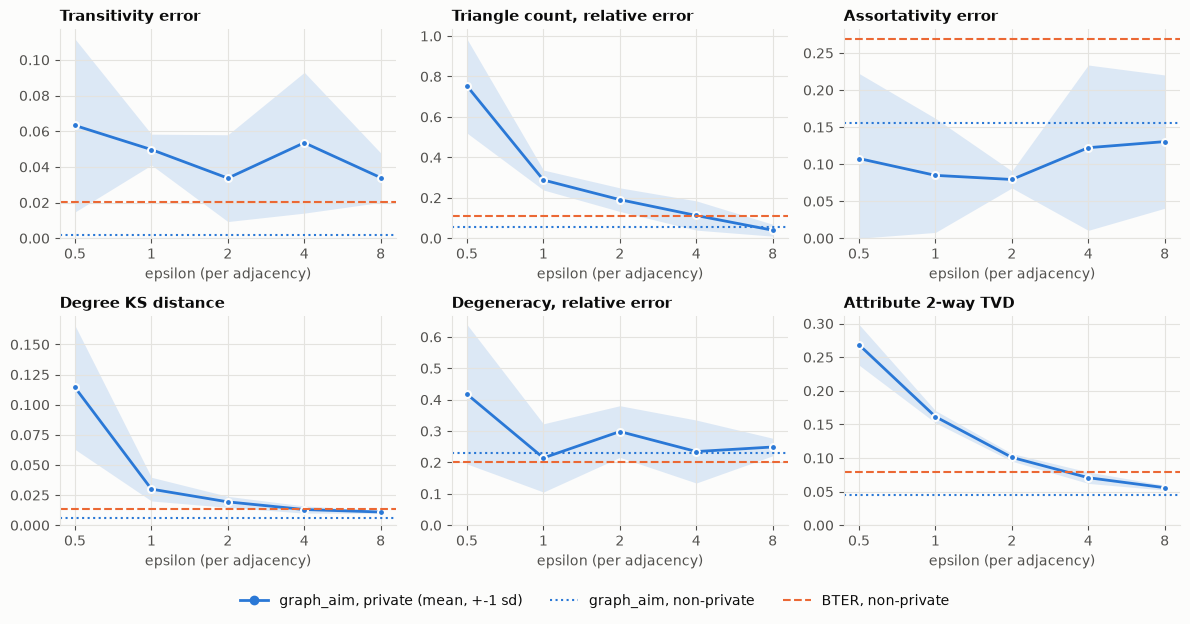

In [3]:
panels = [("transitivity_abs", "Transitivity error"), ("triangles_rel", "Triangle count, relative error"),
          ("assortativity_abs", "Assortativity error"), ("degree_ks", "Degree KS distance"),
          ("degeneracy_rel", "Degeneracy, relative error"), ("attr_tvd_2way_mean", "Attribute 2-way TVD")]
g = summ[summ.method == "graph_aim"].copy()
priv = g[np.isfinite(g.epsilon)].sort_values("epsilon")
nonpriv = g[~np.isfinite(g.epsilon)].iloc[0]
bter = bsumm[bsumm.method == "bter"].iloc[0]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.2))
for ax, (c, title) in zip(axes.ravel(), panels):
    x = priv.epsilon.to_numpy(); y = priv[f"{c}_mean"].to_numpy(); s = priv[f"{c}_std"].to_numpy()
    ax.fill_between(x, np.maximum(y - s, 0), y + s, color=BLUE, alpha=0.15, linewidth=0)
    ax.plot(x, y, color=BLUE, linewidth=2, marker="o", markersize=5, markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.axhline(nonpriv[f"{c}_mean"], color=BLUE, linestyle=":", linewidth=1.5)
    ax.axhline(bter[f"{c}_mean"], color=ORANGE, linestyle="--", linewidth=1.5)
    ax.set_xscale("log"); ax.set_xticks(x); ax.set_xticklabels([f"{v:g}" for v in x]); ax.xaxis.set_minor_locator(plt.NullLocator()); ax.set_ylim(bottom=0)
    ax.set_title(title, loc="left"); ax.set_xlabel("epsilon (per adjacency)")
from matplotlib.lines import Line2D
fig.legend(handles=[Line2D([0], [0], color=BLUE, linewidth=2, marker="o", label="graph_aim, private (mean, +-1 sd)"), Line2D([0], [0], color=BLUE, linestyle=":", linewidth=1.5, label="graph_aim, non-private"), Line2D([0], [0], color=ORANGE, linestyle="--", linewidth=1.5, label="BTER, non-private")], loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.05, 1, 1))

Degree KS, triangle count, and the attribute marginals improve steadily with epsilon and reach the non-private level (dotted blue) at eps of about 4 to 8. Transitivity does not: it stays at 0.03 to 0.05, over ten times its non-private level (0.002), so noise in the clustering measurement still costs accuracy at eps = 8. Degeneracy is limited by the sampler (its non-private error is already 0.23). Assortativity is the odd one out, see the next section.

## 3. Assortativity is dominated by seven hub nodes

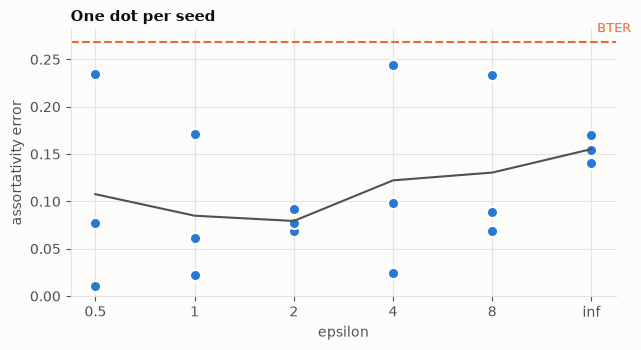

In [4]:
piv = sweep[sweep.method == "graph_aim"].pivot(index="epsilon", columns="seed", values="assortativity_abs")
fig, ax = plt.subplots(figsize=(6.5, 3.6))
xs = np.arange(len(piv))
for j, seed in enumerate(piv.columns):
    ax.plot(xs, piv[seed].to_numpy(), "o", color=BLUE, markersize=8, markeredgecolor=SURFACE, markeredgewidth=1.5)
ax.plot(xs, piv.mean(axis=1).to_numpy(), "-", color=MUTED, linewidth=1.5)
ax.axhline(float(bsumm[bsumm.method == "bter"].assortativity_abs_mean.iloc[0]), color=ORANGE, linestyle="--", linewidth=1.5)
ax.text(len(xs) - 0.6, float(bsumm[bsumm.method == "bter"].assortativity_abs_mean.iloc[0]) + 0.01, "BTER", color=ORANGE, ha="right", fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels(["inf" if not np.isfinite(e) else f"{e:g}" for e in piv.index])
ax.set_xlabel("epsilon"); ax.set_ylabel("assortativity error"); ax.set_ylim(bottom=0)
ax.set_title("One dot per seed", loc="left")
plt.tight_layout()

The real graph has about 7 nodes of degree 275 or more (max 1,045) and they carry the real assortativity of 0.064; the
bulk of the graph alone is 0.61 assortative. The hub count is released through a noisy, pooled degree-histogram tail, so
some seeds get no hubs (large error) and others get them (small error). The mean hides that spread, which is why the
dots are shown separately.

## 4. Degree and clustering profiles

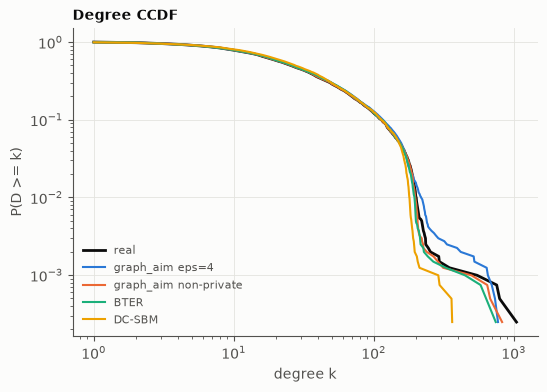

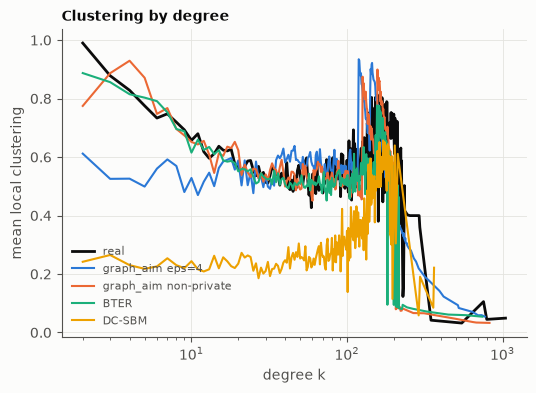

In [5]:
syn = {}
SYN = SNAP.parent / "outside" / "synthetic"  # graphs generated OUTSIDE from the artifacts
from score import align  # synthetic graphs come back with alphabetically sorted attribute columns
syn["graph_aim eps=4"] = align(load_attributed_graph(SYN / "graph_aim_eps4_seed0.npz"), real)
syn["graph_aim non-private"] = align(load_attributed_graph(SYN / "graph_aim_nocap_nonprivate_seed0.npz"), real)
syn["BTER"] = BASELINES["bter"](real, 0)
syn["DC-SBM"] = BASELINES["dc_sbm"](real, 0)
f1 = plot_degree_ccdf(real, syn); f2 = plot_clustering_by_degree(real, syn)

## 5. Empirical privacy diagnostics (not the DP guarantee)

In [6]:
rows = []
for k, a in attacks.items():
    rows.append({"variant": k, "linkage rate (syn)": a["signature_linkage"]["rate_syn"],
                 "linkage rate (holdout)": a["signature_linkage"]["rate_holdout"],
                 "closest-node median ratio": a["closest_node"]["ratio_median"],
                 "closest-node p05 ratio": a["closest_node"]["ratio_p05"], "too close": a["closest_node"]["too_close"]})
pd.DataFrame(rows).set_index("variant").round(3)

,linkage rate (syn),linkage rate (holdout),closest-node median ratio,closest-node p05 ratio,too close
variant,,,,,
graph_aim_eps0.5,0.040,0.077,1.283,2.607,False
graph_aim_eps1.0,0.055,0.077,1.064,1.222,False
graph_aim_eps2.0,0.063,0.077,1.019,1.006,False
graph_aim_eps4.0,0.071,0.077,1.012,0.929,False
graph_aim_eps8.0,0.071,0.077,0.995,0.895,False
graph_aim_epsinf,0.072,0.077,0.989,0.904,False
graph_aim_nocap_nonprivate,0.070,0.077,0.990,0.849,False
erdos_renyi,0.031,0.077,2.284,7.448,False
chung_lu,0.064,0.077,1.747,5.594,False


A ratio above 1 means synthetic nodes are *farther* from real nodes than a held-out half of the real nodes is; none of the
variants is flagged. These checks are heuristics: node ids are not aligned, so edge-level membership inference cannot be
run, and they say nothing about what the DP statement does or does not cover.

## 6. Link-prediction utility (coarse)

In [7]:
u = pd.concat([summ[(summ.method == "graph_aim")][["method", "epsilon", "utility_auc_ratio_mean"]],
               summ[summ.method == "graph_aim_nocap_nonprivate"][["method", "epsilon", "utility_auc_ratio_mean"]],
               bsumm.assign(epsilon=np.nan)[["method", "epsilon", "utility_auc_ratio_mean"]]])
u.round(3).reset_index(drop=True)

,method,epsilon,utility_auc_ratio_mean
0,graph_aim,0.5,0.998
1,graph_aim,1.0,0.998
2,graph_aim,2.0,0.996
3,graph_aim,4.0,0.994
4,graph_aim,8.0,0.993
5,graph_aim,inf,0.989
6,graph_aim_nocap_nonprivate,inf,0.989
7,erdos_renyi,NaN,0.516
8,chung_lu,NaN,0.647
9,dc_sbm,NaN,0.999


A classifier trained on the synthetic graph's pairs and tested on real pairs reaches 0.99 of the real-trained AUC for
every graph-AIM row, and 0.98 to 1.00 for BTER and DC-SBM. This task is dominated by degree and attribute signal and does
not separate the decent methods; use the structure metrics above for comparison.

## 7. The artifact (eps = 4)

In [8]:
print(inspect_report(SNAP.parent / "transfer" / "artifacts" / "graph_aim_eps4_seed0")[:3500])

# Graph-AIM artifact report

## Schema

- nodes (public): 4039
- degree cap D: 100
- cap salt: 20260101
- homophily attributes: school

| attribute | domain size | labels |
|---|---|---|
| birthday | 7 | birthday_5, birthday_6, birthday_4, birthday_7, birthday_210, other, none |
| employer | 7 | employer_140, employer_151, employer_150, employer_52, employer_538, other, none |
| gender | 4 | gender_78, gender_77, other, none |
| hometown | 6 | hometown_84, hometown_908, hometown_935, hometown_359, other, none |
| language | 6 | language_92, language_265, language_90, language_101, other, none |
| locale | 6 | locale_127, locale_278, locale_126, locale_932, other, none |
| location | 7 | location_84, location_176, location_617, location_128, location_908, other, none |
| school | 6 | school_538, school_52, school_50, school_228, other, none |

## Privacy budget

delta = 1e-06. Conversion: eps = rho + 2 sqrt(rho ln(1/delta)).

| adjacency | rho (zCDP) | epsilon |
|---|---|---|
| edge | 0

## 8. Takeaways and limitations

**What works (mean of 3 seeds, eps = 4 per adjacency)**
- Degree distribution: KS 0.013 (BTER 0.014). Triangle count: relative error 0.11 (BTER 0.11).
- Attributes: 2-way TVD 0.071 against about 0.08 for baselines with independent attributes; homophily error 0.26
  against 0.31.
- The artifact is inspectable (noisy tables, noise scales, sensitivities, budgets) and generation works from a copy of
  the artifact alone (stage 2 runs with only `src` importable, see `snap/README.md`).

**What does not**
- Clustering, transitivity, and degeneracy trail non-private BTER; the sampler overshoots degeneracy (about 140 vs 115)
  even without noise.
- Assortativity depends on a handful of hubs and varies a lot across seeds (see section 3).
- Several design parameters were chosen by looking at the real graph and are outside the DP statement.
- Edge-DP and attribute-row DP are stated separately, and the node count is public. Node-DP is not provided.
- Single dataset, single graph. Ego-network structure (10 egos) may bias the statistics being preserved.

**Next steps**: DP selection of attribute domains and caps; node-DP via projection; adaptive (AIM-style) workload
selection; attribute-aware phase-1 blocks (homophily); learned or embedding encoders under DP-SGD.